# Análisis termodinámico del sector phantom en gravedad unimodular con difusión

Modelo:

\[
p=\omega\rho,\qquad Q=\alpha\rho^\beta,\qquad \omega<-1,
\]

\[
3H^2=\rho+Q=\rho F(\rho),
\qquad
F(\rho)=1+\alpha\rho^{\beta-1},
\]

\[
D(\rho)=1+\alpha\beta\rho^{\beta-1},
\]

\[
\dot\rho=-\frac{3H(1+\omega)\rho}{D(\rho)},
\qquad
\dot H=-\frac{1+\omega}{2}\rho.
\]

Este notebook usa el **core existente de `cosmo_singularities`** (`src.models`,
`src.barotropic_analysis`, `src.parameter_space`) y restringe el análisis a
\(\omega<-1\).

## Objetivos

1. Explorar sólo modelos phantom.
2. Identificar las regiones compatibles con la segunda ley para \(T>0\).
3. No confundir \(\dot S\ge0\) con una demostración absoluta de \(S>0\).
4. Mantener explícita la condición de convexidad \(\ddot S<0\), que requiere una ley térmica adicional.
5. Clasificar dinámicamente los candidatos usando el core del proyecto.
6. Analizar explícitamente la familia requerida
   \[
   \boxed{\beta=-1,\quad \alpha<0,\quad D>0},
   \]
   aunque resulte termodinámicamente excluida.
7. Comparar esa familia con las ramas \(\beta=-1,\alpha>0\).

> Convención numérica: \(\rho_0=a_0=1\). Si se trabaja dimensionalmente,
> \(\alpha\) debe interpretarse mediante la combinación adimensional
> \(\bar\alpha=\alpha\rho_0^{\beta-1}\).

## 0. Criterios termodinámicos utilizados

De Gibbs,

\[
TdS=d(\rho V)+p\,dV,
\qquad V\propto a^3,
\]

y usando

\[
\dot\rho+\dot Q+3H(\rho+p)=0,
\]

se obtiene

\[
T\dot S=-V\dot Q.
\]

Para

\[
Q=\alpha\rho^\beta,
\]

\[
\dot S=
\frac{3VH}{T}(1+\omega)
\frac{\alpha\beta\rho^\beta}{D(\rho)}.
\]

Con \(T>0\), \(V>0\), \(H>0\), \(\rho>0\) y \(\omega<-1\),

\[
\boxed{
\dot S\ge0
\iff
\frac{\alpha\beta}{D(\rho)}\le0
}.
\]

En una rama expansiva phantom con \(D_0>0\), la región activa más importante es

\[
\boxed{\alpha\beta<0,\qquad D_0>0}.
\]

### Importante

- \(\dot S\ge0\) **no demuestra por sí sola** \(S>0\).
- Si además se impone \(S_0>0\), entonces \(\dot S\ge0\) preserva \(S>0\).
- La condición de equilibrio/convexidad
  \[
  \ddot S<0
  \]
  necesita conocer \(T(t)\).
- Si se impone además la relación de Euler estándar con \(\mu=0\),
  \[
  TS=(\rho+p)V,
  \]
  entonces para \(\omega<-1\), \(T>0\), \(\rho>0\) se obtiene \(S<0\).
  Por eso el notebook **no declara consistencia termodinámica completa**
  sin especificar el cierre termodinámico.

## 1. Preparación del proyecto

El notebook está pensado para ubicarse dentro de `Cosmo_Singularities_v2/notebooks/`
o ejecutarse desde la raíz `Cosmo_Singularities_v2/`.

In [1]:
from pathlib import Path
import sys
import importlib
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    candidates = [
        PROJECT_ROOT.parent,
        PROJECT_ROOT.parent.parent,
        PROJECT_ROOT / "Cosmo_Singularities_v2",
    ]
    PROJECT_ROOT = next(
        (p for p in candidates if (p / "src").exists()),
        None,
    )

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontró src/. Ejecuta este notebook desde Cosmo_Singularities_v2 "
        "o desde su carpeta notebooks/."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "barotropic_thermodynamics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT =", PROJECT_ROOT)
print("OUTPUT_DIR  =", OUTPUT_DIR)

PROJECT_ROOT = /Users/macbook/Usach/TesisxD/cosmo_singularities
OUTPUT_DIR  = /Users/macbook/Usach/TesisxD/cosmo_singularities/data/processed/barotropic_thermodynamics


In [17]:
import src.models as models_module
import src.barotropic_analysis as analysis_module
import src.parameter_space as parameter_space_module
import src.classifiers as classifiers_module
import src.singularities as singularities_module

from src.models import (
    BarotropicPowerDiffusionParams,
    BarotropicPowerDiffusionModel,
)

from src.barotropic_analysis import (
    analyze_barotropic_case,
    compute_critical_densities,
)

from src.parameter_space import (
    build_parameter_grid,
    analyze_parameter_grid,
    behavior_matrix,
    encode_behavior_matrix,
)

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 250)

print("Core barotrópico importado correctamente.")

from src.models import (
    BarotropicPowerDiffusionParams,
    BarotropicPowerDiffusionModel,
)
from src.barotropic_analysis import (
    analyze_barotropic_case,
    compute_critical_densities,
)
from src.parameter_space import (
    build_parameter_grid,
    analyze_parameter_grid,
    behavior_matrix,
    encode_behavior_matrix,
)

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 250)

print("Core barotrópico importado correctamente.")

Core barotrópico importado correctamente.
Core barotrópico importado correctamente.


## 2. Funciones termodinámicas

Definimos una cantidad reducida

\[
\Sigma(\rho)
\equiv
\frac{T}{3VH}\dot S
=
(1+\omega)\frac{\alpha\beta\rho^\beta}{D(\rho)}.
\]

Como \(3VH/T>0\), el signo de \(\Sigma\) es exactamente el signo de \(\dot S\).

Esto permite estudiar la segunda ley **sin inventar una ley de temperatura**.

In [3]:
THERMO_TOL = 1e-12

def entropy_production_reduced(omega, alpha, beta, rho):
    """Sigma = (T/(3 V H)) dot(S). Su signo coincide con dot(S) para T,V,H>0."""
    rho = np.asarray(rho, dtype=float)
    D = 1.0 + alpha * beta * rho ** (beta - 1.0)
    return (1.0 + omega) * alpha * beta * rho**beta / D

def thermo_point_status(omega, alpha, beta, rho=1.0, tol=THERMO_TOL):
    """Diagnóstico local en una densidad dada, restringido a omega < -1."""
    F = 1.0 + alpha * rho ** (beta - 1.0)
    D = 1.0 + alpha * beta * rho ** (beta - 1.0)

    if not (omega < -1.0):
        return {
            "phantom": False,
            "F": F,
            "D": D,
            "physical": False,
            "active_diffusion": abs(alpha * beta) > tol,
            "sigma": np.nan,
            "second_law": "out_of_scope",
        }

    physical = F > 0.0 and abs(D) > tol

    if not physical:
        second_law = "invalid_domain"
        sigma = np.nan
    elif abs(alpha * beta) <= tol:
        sigma = 0.0
        second_law = "saturated_no_active_Qdot"
    else:
        sigma = float(entropy_production_reduced(omega, alpha, beta, rho))
        second_law = "satisfied" if sigma >= -tol else "violated"

    return {
        "phantom": True,
        "F": F,
        "D": D,
        "physical": physical,
        "active_diffusion": abs(alpha * beta) > tol,
        "sigma": sigma,
        "second_law": second_law,
    }

def add_thermodynamic_columns(df, tol=THERMO_TOL):
    """Añade criterios termodinámicos al DataFrame generado por parameter_space.py."""
    out = df.copy()

    out["phantom"] = out["omega"] < -1.0
    out["alpha_beta"] = out["alpha"] * out["beta"]

    numerator = (
        (1.0 + out["omega"])
        * out["alpha_beta"]
        * out["rho0"] ** out["beta"]
    )

    out["sigma0"] = np.where(
        np.abs(out["D0"]) > tol,
        numerator / out["D0"],
        np.nan,
    )

    out["active_diffusion"] = np.abs(out["alpha_beta"]) > tol

    out["second_law_initial"] = (
        out["valid_initial_domain"]
        & out["phantom"]
        & (out["sigma0"] >= -tol)
    )

    # Candidato robusto para difusión activa:
    # omega < -1, alpha*beta < 0, D0 > 0 y dominio físico.
    out["thermo_candidate_active"] = (
        out["valid_initial_domain"]
        & out["phantom"]
        & (out["alpha_beta"] < -tol)
        & (out["D0"] > tol)
    )

    out["second_law_saturated"] = (
        out["valid_initial_domain"]
        & out["phantom"]
        & (~out["active_diffusion"])
    )

    out["S_positive_statement"] = np.where(
        out["second_law_initial"],
        "preserved_if_S0_positive",
        "not_guaranteed",
    )

    out["convexity_statement"] = "requires_T_law"

    # Si se impone Euler estándar con mu=0 y T>0:
    out["euler_mu0_Tpos_Spos"] = False

    def label(row):
        if not row["valid_initial_domain"]:
            return "invalid_initial_domain"
        if not row["phantom"]:
            return "out_of_scope"
        if row["second_law_saturated"]:
            return "second_law_saturated"
        if row["thermo_candidate_active"]:
            return "second_law_candidate"
        return "second_law_violated"

    out["thermo_label"] = out.apply(label, axis=1)
    return out

## 3. Condición de convexidad sin fijar todavía \(T(t)\)

En una región con \(\dot S>0\),

\[
\frac{\ddot S}{\dot S}
=
H\left[
3+\frac{3\gamma}{2F}
+\frac{3\gamma}{D}
\left(1+\frac{\beta-1}{D}\right)
\right]
-\frac{\dot T}{T},
\]

donde

\[
\gamma=-(1+\omega)>0.
\]

Definimos

\[
\Theta_T\equiv \frac{\dot T}{HT}.
\]

Entonces la convexidad

\[
\ddot S<0
\]

requiere

\[
\boxed{
\Theta_T >
3+\frac{3\gamma}{2F}
+\frac{3\gamma}{D}
\left(1+\frac{\beta-1}{D}\right)
}.
\]

El notebook calcula este umbral, pero **no supone** una ley \(T(t)\).

In [4]:
def theta_T_required(omega, alpha, beta, rho):
    """Umbral de Theta_T = dot(T)/(H T) requerido para ddot(S)<0 si dot(S)>0."""
    rho = np.asarray(rho, dtype=float)
    gamma = -(1.0 + omega)
    F = 1.0 + alpha * rho ** (beta - 1.0)
    D = 1.0 + alpha * beta * rho ** (beta - 1.0)

    return (
        3.0
        + 3.0 * gamma / (2.0 * F)
        + 3.0 * gamma / D * (1.0 + (beta - 1.0) / D)
    )

## 4. Configuración del barrido phantom

El modo `pilot` es recomendable para verificar el flujo.  
El modo `full` usa la misma filosofía del notebook científico anterior, pero sólo con \(\omega<-1\).

In [5]:
SCAN_MODE = "pilot"   # "pilot" o "full"

OMEGA_VALUES = np.array([-1.4, -1.2, -1.05])

if SCAN_MODE == "pilot":
    ALPHA_VALUES = np.unique(np.concatenate([
        np.linspace(-0.9, -0.1, 9),
        np.array([0.0, 0.1, 0.25, 0.5, 0.9, 1.1, 2.0, 4.0]),
    ]))
    BETA_VALUES = np.unique(np.concatenate([
        np.linspace(-2.0, 3.0, 21),
        np.array([-1.0, 0.0, 1.0, 2.0]),
    ]))
    ANALYSIS_KWARGS = {
        "t_end": 30.0,
        "n_points": 1800,
        "max_step": 0.01,
        "density_decades": 8,
        "boundary_tolerances": [1e-2, 1e-3, 1e-4, 1e-5, 1e-6],
        "collapse_rho_max_values": [1e2, 1e3, 1e4, 1e5, 1e6],
    }
elif SCAN_MODE == "full":
    ALPHA_VALUES = np.unique(np.concatenate([
        np.linspace(-0.95, -0.05, 19),
        np.array([0.0]),
        np.linspace(0.05, 4.0, 40),
    ]))
    BETA_VALUES = np.unique(np.concatenate([
        np.linspace(-2.0, 3.0, 51),
        np.array([-1.0, 0.0, 1.0, 2.0]),
    ]))
    ANALYSIS_KWARGS = {
        "t_end": 60.0,
        "n_points": 3000,
        "max_step": 0.005,
        "density_decades": 10,
        "boundary_tolerances": [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7],
        "collapse_rho_max_values": [1e2, 1e3, 1e4, 1e5, 1e6, 1e7],
    }
else:
    raise ValueError("SCAN_MODE debe ser 'pilot' o 'full'.")

print("SCAN_MODE =", SCAN_MODE)
print("N alpha =", len(ALPHA_VALUES))
print("N beta  =", len(BETA_VALUES))
print("N omega =", len(OMEGA_VALUES))
print("Puntos brutos =", len(ALPHA_VALUES) * len(BETA_VALUES) * len(OMEGA_VALUES))

SCAN_MODE = pilot
N alpha = 17
N beta  = 21
N omega = 3
Puntos brutos = 1071


## 5. Construcción de la grilla con el core y filtro termodinámico

In [6]:
parameter_grid = build_parameter_grid(
    alpha_values=ALPHA_VALUES,
    beta_values=BETA_VALUES,
    omega_values=OMEGA_VALUES,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
)

parameter_grid = add_thermodynamic_columns(parameter_grid)

print("Puntos totales:", len(parameter_grid))
print("Dominio inicial válido:", int(parameter_grid["valid_initial_domain"].sum()))
print("Candidatos activos a segunda ley:", int(parameter_grid["thermo_candidate_active"].sum()))
print("Segunda ley saturada:", int(parameter_grid["second_law_saturated"].sum()))
print("Violación inicial de segunda ley:",
      int((parameter_grid["thermo_label"] == "second_law_violated").sum()))

display(
    parameter_grid[
        [
            "omega", "alpha", "beta", "F0", "D0", "sigma0",
            "thermo_label", "S_positive_statement", "convexity_statement"
        ]
    ].head(30)
)

Puntos totales: 1071
Dominio inicial válido: 1053
Candidatos activos a segunda ley: 306
Segunda ley saturada: 111
Violación inicial de segunda ley: 636


,omega,alpha,beta,F0,D0,sigma0,thermo_label,S_positive_statement,convexity_statement
0,-1.4,-0.90,-2.00,0.10,2.8000,-0.257143,second_law_violated,not_guaranteed,requires_T_law
1,-1.4,-0.80,-2.00,0.20,2.6000,-0.246154,second_law_violated,not_guaranteed,requires_T_law
2,-1.4,-0.70,-2.00,0.30,2.4000,-0.233333,second_law_violated,not_guaranteed,requires_T_law
3,-1.4,-0.60,-2.00,0.40,2.2000,-0.218182,second_law_violated,not_guaranteed,requires_T_law
4,-1.4,-0.50,-2.00,0.50,2.0000,-0.200000,second_law_violated,not_guaranteed,requires_T_law
5,-1.4,-0.40,-2.00,0.60,1.8000,-0.177778,second_law_violated,not_guaranteed,requires_T_law
6,-1.4,-0.30,-2.00,0.70,1.6000,-0.150000,second_law_violated,not_guaranteed,requires_T_law
7,-1.4,-0.20,-2.00,0.80,1.4000,-0.114286,second_law_violated,not_guaranteed,requires_T_law
8,-1.4,-0.10,-2.00,0.90,1.2000,-0.066667,second_law_violated,not_guaranteed,requires_T_law
9,-1.4,0.00,-2.00,1.00,1.0000,0.000000,second_law_saturated,preserved_if_S0_positive,requires_T_law


### Lectura del filtro

Para difusión activa y phantom:

\[
\boxed{
\text{candidato a segunda ley}
\Longleftrightarrow
\alpha\beta<0,\quad D_0>0,\quad F_0>0.
}
\]

Los puntos candidatos **no se etiquetan como completamente termodinámicos**:
la convexidad sigue dependiendo de \(T(t)\), y la positividad absoluta de \(S\)
requiere una condición inicial \(S_0>0\) o un cierre termodinámico adicional.

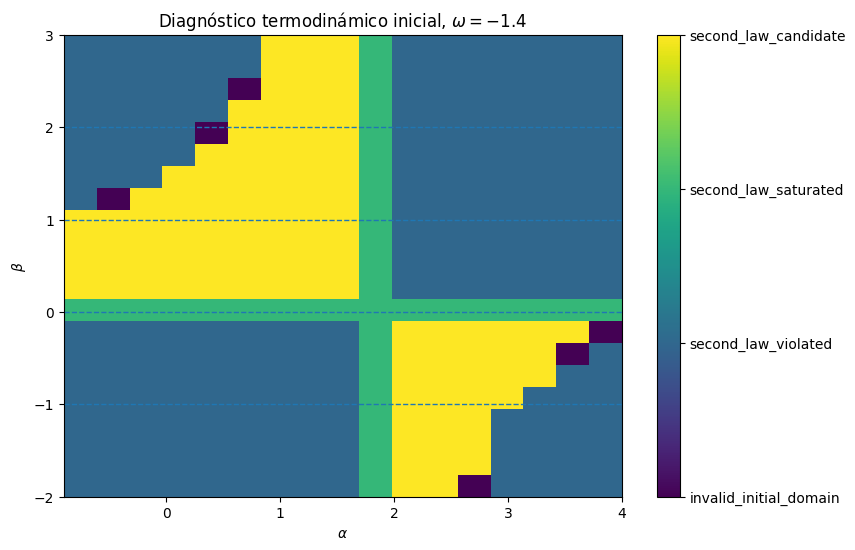

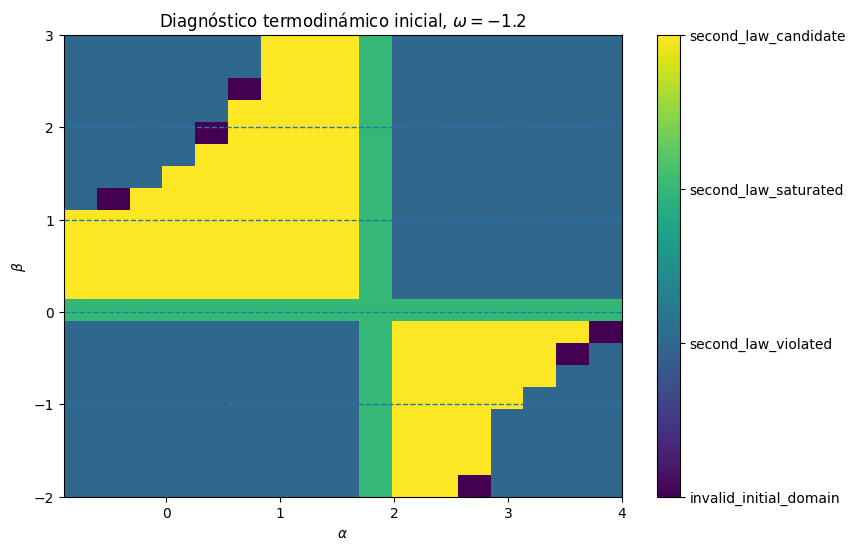

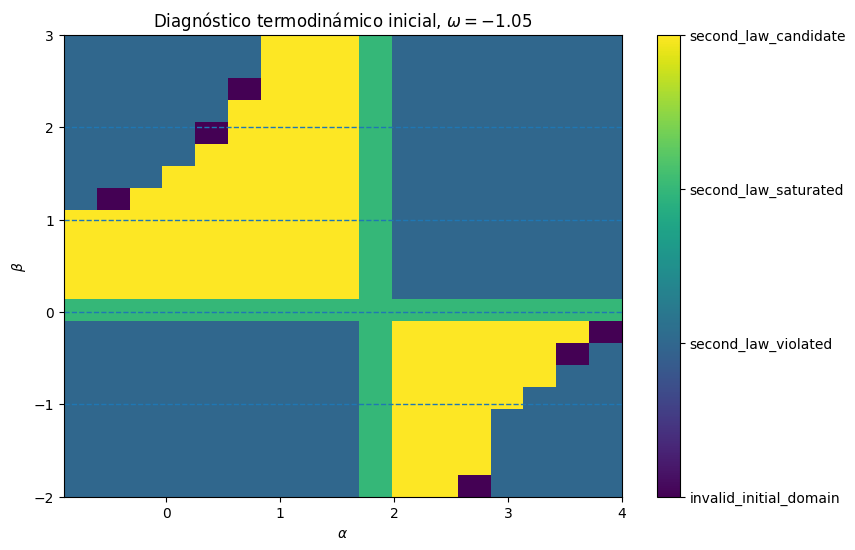

In [7]:
def plot_thermo_map(grid, omega):
    sliced = grid[np.isclose(grid["omega"], omega, atol=1e-12, rtol=0.0)].copy()

    pivot = sliced.pivot_table(
        index="beta",
        columns="alpha",
        values="thermo_label",
        aggfunc="first",
    ).sort_index().sort_index(axis=1)

    labels = [
        "invalid_initial_domain",
        "second_law_violated",
        "second_law_saturated",
        "second_law_candidate",
    ]
    label_to_code = {label: i for i, label in enumerate(labels)}

    encoded = np.full(pivot.shape, np.nan)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            value = pivot.iat[i, j]
            if pd.notna(value) and value in label_to_code:
                encoded[i, j] = label_to_code[value]

    alphas = pivot.columns.to_numpy(dtype=float)
    betas = pivot.index.to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(9, 6))
    im = ax.imshow(
        encoded,
        origin="lower",
        aspect="auto",
        extent=[alphas.min(), alphas.max(), betas.min(), betas.max()],
        interpolation="nearest",
    )
    ax.axhline(-1.0, linestyle="--", linewidth=1.0)
    ax.axhline(0.0, linestyle="--", linewidth=1.0)
    ax.axhline(1.0, linestyle="--", linewidth=1.0)
    ax.axhline(2.0, linestyle="--", linewidth=1.0)
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(r"$\beta$")
    ax.set_title(rf"Diagnóstico termodinámico inicial, $\omega={omega:g}$")

    cbar = fig.colorbar(im, ax=ax)
    ticks = list(range(len(labels)))
    cbar.set_ticks(ticks)
    cbar.set_ticklabels(labels)
    plt.show()

for omega in OMEGA_VALUES:
    plot_thermo_map(parameter_grid, omega)

## 6. Barrido dinámico sólo de candidatos + controles científicos

Para no gastar tiempo numérico en puntos que la segunda ley ya excluye,
el análisis dinámico completo se ejecuta sobre:

1. candidatos activos a segunda ley;
2. puntos de saturación;
3. controles \(eta=-1,lpha<0,D_0>0\);
4. algunos controles \(eta=-1,lpha>0\) para comparación.

In [8]:
special_beta_minus_one_negative_alpha = (
    parameter_grid["valid_initial_domain"]
    & np.isclose(parameter_grid["beta"], -1.0, atol=1e-12, rtol=0.0)
    & (parameter_grid["alpha"] < 0.0)
    & (parameter_grid["D0"] > 0.0)
)

special_beta_minus_one_positive_alpha = (
    parameter_grid["valid_initial_domain"]
    & np.isclose(parameter_grid["beta"], -1.0, atol=1e-12, rtol=0.0)
    & (parameter_grid["alpha"] > 0.0)
)

focus_mask = (
    parameter_grid["thermo_candidate_active"]
    | parameter_grid["second_law_saturated"]
    | special_beta_minus_one_negative_alpha
    | special_beta_minus_one_positive_alpha
)

focus_grid = parameter_grid.loc[focus_mask].copy()

print("Puntos enviados al core dinámico:", len(focus_grid))
print("De ellos, beta=-1 y alpha<0 con D0>0:",
      int(special_beta_minus_one_negative_alpha.sum()))

Puntos enviados al core dinámico: 453
De ellos, beta=-1 y alpha<0 con D0>0: 27


In [9]:
RUN_DYNAMIC_SCAN = True

checkpoint = OUTPUT_DIR / f"phantom_thermo_focus_{SCAN_MODE}.csv"

if RUN_DYNAMIC_SCAN:
    parameter_results = analyze_parameter_grid(
        focus_grid,
        analysis_kwargs=ANALYSIS_KWARGS,
        checkpoint_path=checkpoint,
        resume=True,
        checkpoint_every=20,
        verbose=True,
    )
else:
    parameter_results = pd.read_csv(checkpoint)

parameter_results = parameter_results.merge(
    focus_grid[
        [
            "point_id", "alpha_beta", "sigma0", "thermo_label",
            "second_law_initial", "thermo_candidate_active",
            "S_positive_statement", "convexity_statement",
            "euler_mu0_Tpos_Spos",
        ]
    ],
    on="point_id",
    how="left",
)

print("Resultados dinámicos:", parameter_results.shape)

Puntos almacenados: 50 / 453
Puntos almacenados: 100 / 453
Puntos almacenados: 150 / 453
Puntos almacenados: 200 / 453
Puntos almacenados: 250 / 453
Puntos almacenados: 300 / 453
Puntos almacenados: 350 / 453
Puntos almacenados: 400 / 453
Puntos almacenados: 450 / 453
Resultados dinámicos: (453, 43)


## 7. Resumen de destinos cosmológicos dentro de la región candidata

In [10]:
candidate_results = parameter_results[
    parameter_results["thermo_candidate_active"]
].copy()

candidate_summary = (
    candidate_results
    .groupby(["omega", "behavior_label"], dropna=False)
    .size()
    .rename("count")
    .reset_index()
    .sort_values(["omega", "count"], ascending=[True, False])
)

display(candidate_summary)

,omega,behavior_label,count
0,-1.40,analysis_error,102
1,-1.20,analysis_error,102
2,-1.05,analysis_error,102


In [11]:
candidate_table_columns = [
    "omega", "alpha", "beta", "F0", "D0", "sigma0",
    "behavior_label", "standard_type", "finite_time", "time_limit",
    "rho_limit", "a_limit", "H_limit", "Hdot_limit",
    "confidence",
]

display(
    candidate_results[candidate_table_columns]
    .sort_values(["omega", "beta", "alpha"])
)

,omega,alpha,beta,F0,D0,sigma0,behavior_label,standard_type,finite_time,time_limit,rho_limit,a_limit,H_limit,Hdot_limit,confidence
1,-1.40,0.10,-2.00,1.10,0.8000,0.100000,analysis_error,None,None,unknown,unknown,unknown,unknown,unknown,0.0
2,-1.40,0.25,-2.00,1.25,0.5000,0.400000,analysis_error,None,None,unknown,unknown,unknown,unknown,unknown,0.0
4,-1.40,0.10,-1.75,1.10,0.8250,0.084848,analysis_error,None,None,unknown,unknown,unknown,unknown,unknown,0.0
5,-1.40,0.25,-1.75,1.25,0.5625,0.311111,analysis_error,None,None,unknown,unknown,unknown,unknown,unknown,0.0
6,-1.40,0.50,-1.75,1.50,0.1250,2.800000,analysis_error,None,None,unknown,unknown,unknown,unknown,unknown,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
446,-1.05,-0.20,2.75,0.80,0.4500,0.061111,analysis_error,None,None,unknown,unknown,unknown,unknown,unknown,0.0
447,-1.05,-0.10,2.75,0.90,0.7250,0.018966,analysis_error,None,None,unknown,unknown,unknown,unknown,unknown,0.0
449,-1.05,-0.30,3.00,0.70,0.1000,0.450000,analysis_error,None,None,unknown,unknown,unknown,unknown,unknown,0.0
450,-1.05,-0.20,3.00,0.80,0.4000,0.075000,analysis_error,None,None,unknown,unknown,unknown,unknown,unknown,0.0


## 8. Familia central: \(\beta=-1\)

Para \(\beta=-1\),

\[
Q=\alpha\rho^{-1},
\]

\[
F=1+\alpha\rho^{-2},
\qquad
D=1-\alpha\rho^{-2}.
\]

### Caso solicitado: \(\alpha<0\)

Si

\[
-1<\alpha<0,\qquad \rho_0=1,
\]

entonces

\[
F_0=1+\alpha>0,
\]

y

\[
D_0=1-\alpha>1>0.
\]

Por tanto es un dominio cosmológico real y \(D>0\).

Pero

\[
\alpha\beta=(-)(-) > 0.
\]

Para phantom,

\[
\dot S\ge0
\iff
\frac{\alpha\beta}{D}\le0.
\]

Como aquí

\[
\frac{\alpha\beta}{D}>0,
\]

se predice

\[
\boxed{\dot S<0}.
\]

Este sector se mantiene en el notebook como **control físico importante**:
es dinámicamente válido pero termodinámicamente excluido por la segunda ley
bajo \(T>0\).

In [12]:
beta_m1_results = parameter_results[
    np.isclose(parameter_results["beta"], -1.0, atol=1e-12, rtol=0.0)
].copy()

display(
    beta_m1_results[
        [
            "omega", "alpha", "beta", "F0", "D0", "alpha_beta",
            "sigma0", "thermo_label", "behavior_label", "standard_type",
            "finite_time", "time_limit", "confidence",
        ]
    ].sort_values(["omega", "alpha"])
)

,omega,alpha,beta,F0,D0,alpha_beta,sigma0,thermo_label,behavior_label,standard_type,finite_time,time_limit,confidence
15,-1.40,-0.90,-1.0,0.10,1.90,0.90,-0.189474,second_law_violated,analysis_error,None,None,unknown,0.0
16,-1.40,-0.80,-1.0,0.20,1.80,0.80,-0.177778,second_law_violated,analysis_error,None,None,unknown,0.0
17,-1.40,-0.70,-1.0,0.30,1.70,0.70,-0.164706,second_law_violated,analysis_error,None,None,unknown,0.0
18,-1.40,-0.60,-1.0,0.40,1.60,0.60,-0.150000,second_law_violated,analysis_error,None,None,unknown,0.0
19,-1.40,-0.50,-1.0,0.50,1.50,0.50,-0.133333,second_law_violated,analysis_error,None,None,unknown,0.0
20,-1.40,-0.40,-1.0,0.60,1.40,0.40,-0.114286,second_law_violated,analysis_error,None,None,unknown,0.0
21,-1.40,-0.30,-1.0,0.70,1.30,0.30,-0.092308,second_law_violated,analysis_error,None,None,unknown,0.0
22,-1.40,-0.20,-1.0,0.80,1.20,0.20,-0.066667,second_law_violated,analysis_error,None,None,unknown,0.0
23,-1.40,-0.10,-1.0,0.90,1.10,0.10,-0.036364,second_law_violated,analysis_error,None,None,unknown,0.0
24,-1.40,0.00,-1.0,1.00,1.00,-0.00,0.000000,second_law_saturated,analysis_error,None,None,unknown,0.0


In [13]:
def beta_minus_one_line_table(omega=-1.2):
    alphas = np.array([
        -0.9, -0.7, -0.5, -0.3, -0.1,
         0.1,  0.25, 0.5, 0.9, 1.1, 2.0, 4.0
    ])
    rows = []

    for alpha in alphas:
        beta = -1.0
        status = thermo_point_status(omega, alpha, beta, rho=1.0)
        rows.append({
            "omega": omega,
            "alpha": alpha,
            "beta": beta,
            "F0": status["F"],
            "D0": status["D"],
            "alpha_beta": alpha * beta,
            "sigma0": status["sigma"],
            "second_law": status["second_law"],
        })

    return pd.DataFrame(rows)

display(beta_minus_one_line_table(-1.2))

,omega,alpha,beta,F0,D0,alpha_beta,sigma0,second_law
0,-1.2,-0.90,-1.0,0.10,1.90,0.90,-0.094737,violated
1,-1.2,-0.70,-1.0,0.30,1.70,0.70,-0.082353,violated
2,-1.2,-0.50,-1.0,0.50,1.50,0.50,-0.066667,violated
3,-1.2,-0.30,-1.0,0.70,1.30,0.30,-0.046154,violated
4,-1.2,-0.10,-1.0,0.90,1.10,0.10,-0.018182,violated
5,-1.2,0.10,-1.0,1.10,0.90,-0.10,0.022222,satisfied
6,-1.2,0.25,-1.0,1.25,0.75,-0.25,0.066667,satisfied
7,-1.2,0.50,-1.0,1.50,0.50,-0.50,0.200000,satisfied
8,-1.2,0.90,-1.0,1.90,0.10,-0.90,1.800000,satisfied
9,-1.2,1.10,-1.0,2.10,-0.10,-1.10,-2.200000,violated


### Comparación conceptual para \(\beta=-1\)

Con \(\rho_0=1\):

- \(-1<\alpha<0\): \(F_0>0,\ D_0>0\), pero \(\dot S<0\).
- \(0<\alpha<1\): \(F_0>0,\ D_0>0\) y \(\dot S>0\).
- \(\alpha>1\): \(D_0<0\), correspondiente a la rama de densidad decreciente
  asociada al rip dominado por difusión; allí \(\dot S<0\).

Por eso la familia \(\beta=-1\) es particularmente útil para visualizar
cómo el signo de \(D\) y el signo de \(\alpha\beta\) controlan la segunda ley.

## 9. Casos representativos termodinámicos y de exclusión

In [20]:
REPRESENTATIVE_CASES = {
    # Candidato termodinámico beta=-1: segunda ley satisfecha
    "T1_beta_m1_alpha_pos": BarotropicPowerDiffusionParams(
        omega=-1.2, alpha=0.25, beta=-1.0, rho0=1.0, a0=1.0, t0=0.0
    ),

    # Caso solicitado explícitamente: beta=-1, alpha<0, D>0
    "X1_beta_m1_alpha_neg": BarotropicPowerDiffusionParams(
        omega=-1.2, alpha=-0.30, beta=-1.0, rho0=1.0, a0=1.0, t0=0.0
    ),

    # Otro control más cercano a F=0 inicial
    "X2_beta_m1_alpha_neg": BarotropicPowerDiffusionParams(
        omega=-1.2, alpha=-0.70, beta=-1.0, rho0=1.0, a0=1.0, t0=0.0
    ),

    # Candidato con alpha<0, beta>1: segunda ley satisfecha hasta D->0
    "T2_typeIV_candidate": BarotropicPowerDiffusionParams(
        omega=-1.2, alpha=-0.30, beta=1.5, rho0=1.0, a0=1.0, t0=0.0
    ),

    # Control: alpha>0, beta>0, segunda ley violada
    "X3_positive_positive": BarotropicPowerDiffusionParams(
        omega=-1.2, alpha=0.30, beta=1.5, rho0=1.0, a0=1.0, t0=0.0
    ),

    # Rip dominado por difusión
    "X4_diffusion_rip": BarotropicPowerDiffusionParams(
        omega=-1.2, alpha=4.0, beta=-1.0, rho0=1.0, a0=1.0, t0=0.0
    ),
}

rep_rows = []

for case_id, params in REPRESENTATIVE_CASES.items():
    model = BarotropicPowerDiffusionModel(params)
    crit = compute_critical_densities(params)
    status = thermo_point_status(
        params.omega, params.alpha, params.beta, rho=params.rho0
    )
    analysis = analyze_barotropic_case(
        params=params,
        case_id=case_id,
        **ANALYSIS_KWARGS,
    )

    summary = analysis.summary_dict()

    rep_rows.append({
        "case_id": case_id,
        "omega": params.omega,
        "alpha": params.alpha,
        "beta": params.beta,
        "F0": model.F(params.rho0),
        "D0": model.D(params.rho0),
        "sigma0": status["sigma"],
        "second_law": status["second_law"],
        "rho_F": crit.rho_F,
        "rho_D": crit.rho_D,
        "behavior_label": summary.get("behavior_label"),
        "standard_type": summary.get("standard_type"),
        "finite_time": summary.get("finite_time"),
        "time_limit": summary.get("time_limit"),
        "confidence": summary.get("confidence"),
    })

representative_summary = pd.DataFrame(rep_rows)
display(representative_summary)

TypeError: behavior_label debe ser una cadena o un miembro de KnownCosmologicalBehavior.

## 10. Evolución temporal con el modelo del core

Se grafica una cantidad termodinámica reducida

\[
\Sigma(t)=
rac{T}{3VH}\dot S,
\]

por lo que no es necesario fijar \(T(t)\) para decidir el signo de la segunda ley.

In [ ]:
def solve_case_background(params, t_end=20.0, n_points=2000):
    model = BarotropicPowerDiffusionModel(params)

    bg = model.solve_background_t(
        t_end=t_end,
        n_points=n_points,
        rho_min=1e-12,
        rho_max=1e8,
        a_max=1e12,
        boundary_tol=1e-8,
        method="DOP853",
        rtol=1e-9,
        atol=1e-11,
        max_step=0.01,
    ).copy()

    bg["F"] = model.F(bg["rho"].to_numpy())
    bg["D"] = model.D(bg["rho"].to_numpy())
    bg["Q"] = params.alpha * bg["rho"] ** params.beta
    bg["sigma_reduced"] = entropy_production_reduced(
        params.omega,
        params.alpha,
        params.beta,
        bg["rho"].to_numpy(),
    )
    bg["theta_T_required"] = theta_T_required(
        params.omega,
        params.alpha,
        params.beta,
        bg["rho"].to_numpy(),
    )

    return bg

def plot_case_thermodynamics(case_id, params, t_end=20.0):
    bg = solve_case_background(params, t_end=t_end)

    fig, axs = plt.subplots(2, 2, figsize=(13, 8))

    axs[0, 0].plot(bg["t"], bg["rho"])
    axs[0, 0].set_yscale("log")
    axs[0, 0].set_xlabel("t")
    axs[0, 0].set_ylabel(r"$\rho$")
    axs[0, 0].set_title("Densidad")

    axs[0, 1].plot(bg["t"], bg["D"])
    axs[0, 1].axhline(0.0, linestyle="--", linewidth=1)
    axs[0, 1].set_xlabel("t")
    axs[0, 1].set_ylabel(r"$D(\rho)$")
    axs[0, 1].set_title("Denominador dinámico")

    axs[1, 0].plot(bg["t"], bg["sigma_reduced"])
    axs[1, 0].axhline(0.0, linestyle="--", linewidth=1)
    axs[1, 0].set_xlabel("t")
    axs[1, 0].set_ylabel(r"$\Sigma=(T/3VH)\dot S$")
    axs[1, 0].set_title("Signo de producción de entropía")

    axs[1, 1].plot(bg["t"], bg["theta_T_required"])
    axs[1, 1].set_xlabel("t")
    axs[1, 1].set_ylabel(r"$\Theta_{T,\min}$")
    axs[1, 1].set_title(r"Umbral para $\ddot S<0$")

    fig.suptitle(
        rf"{case_id}: $\omega={params.omega}$, "
        rf"$\alpha={params.alpha}$, $\beta={params.beta}$"
    )
    fig.tight_layout()
    plt.show()

    print("Evento de integración:", bg.attrs.get("termination_event"))
    print("Mensaje:", bg.attrs.get("message"))
    return bg

In [ ]:
# Ejecuta por defecto los dos casos beta=-1 más importantes:
bg_T1 = plot_case_thermodynamics(
    "T1_beta_m1_alpha_pos",
    REPRESENTATIVE_CASES["T1_beta_m1_alpha_pos"],
    t_end=20.0,
)

bg_X1 = plot_case_thermodynamics(
    "X1_beta_m1_alpha_neg",
    REPRESENTATIVE_CASES["X1_beta_m1_alpha_neg"],
    t_end=20.0,
)

## 11. Comprobación explícita del caso requerido \(\beta=-1,\alpha<0,D>0\)

Para este caso el notebook debe verificar numéricamente tres hechos:

1. \(F>0\) sobre la trayectoria integrada.
2. \(D>0\) sobre la trayectoria integrada.
3. \(\Sigma<0\), es decir, \(\dot S<0\) para \(T>0\).

Si se cumplen los tres, el resultado es físicamente muy útil:
**el modelo es dinámicamente admisible pero queda excluido por la segunda ley
en la formulación termodinámica adoptada.**

In [ ]:
def check_required_beta_minus_one_case(bg, params):
    checks = {
        "omega< -1": params.omega < -1.0,
        "beta == -1": np.isclose(params.beta, -1.0),
        "alpha < 0": params.alpha < 0.0,
        "F > 0 en trayectoria": bool(np.all(bg["F"].to_numpy() > 0.0)),
        "D > 0 en trayectoria": bool(np.all(bg["D"].to_numpy() > 0.0)),
        "Sigma < 0 en trayectoria": bool(np.all(bg["sigma_reduced"].to_numpy() < 0.0)),
    }

    return pd.DataFrame(
        {"condicion": list(checks.keys()), "cumple": list(checks.values())}
    )

display(
    check_required_beta_minus_one_case(
        bg_X1,
        REPRESENTATIVE_CASES["X1_beta_m1_alpha_neg"],
    )
)

## 12. Mapa de destinos sólo dentro de candidatos a segunda ley

Este mapa ya no muestra todo el espacio cosmológico: muestra únicamente
los puntos que pasan el filtro termodinámico mínimo.

In [ ]:
def plot_candidate_fate_map(results, omega):
    sliced = results[
        np.isclose(results["omega"], omega, atol=1e-12, rtol=0.0)
        & results["thermo_candidate_active"]
    ].copy()

    if sliced.empty:
        print(f"No hay candidatos para omega={omega}.")
        return

    pivot = sliced.pivot_table(
        index="beta",
        columns="alpha",
        values="behavior_label",
        aggfunc="first",
    ).sort_index().sort_index(axis=1)

    labels = sorted({
        str(v) for v in pivot.to_numpy().ravel()
        if pd.notna(v)
    })
    label_to_code = {label: i for i, label in enumerate(labels)}

    encoded = np.full(pivot.shape, np.nan)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            value = pivot.iat[i, j]
            if pd.notna(value):
                encoded[i, j] = label_to_code[str(value)]

    alphas = pivot.columns.to_numpy(dtype=float)
    betas = pivot.index.to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(9, 6))
    im = ax.imshow(
        encoded,
        origin="lower",
        aspect="auto",
        extent=[alphas.min(), alphas.max(), betas.min(), betas.max()],
        interpolation="nearest",
    )
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(r"$\beta$")
    ax.set_title(
        rf"Destinos dentro de $\dot S\geq0$, $\omega={omega:g}$"
    )

    cbar = fig.colorbar(im, ax=ax)
    ticks = list(range(len(labels)))
    cbar.set_ticks(ticks)
    cbar.set_ticklabels(labels)
    plt.show()

for omega in OMEGA_VALUES:
    plot_candidate_fate_map(parameter_results, omega)

## 13. Auditoría de la condición de segunda ley a lo largo de trayectorias

Para cada caso representativo se muestrea \(D(
ho)\) y \(\Sigma(
ho)\)
sobre la evolución obtenida con `BarotropicPowerDiffusionModel`.

In [ ]:
trajectory_audit_rows = []

for case_id, params in REPRESENTATIVE_CASES.items():
    try:
        bg = solve_case_background(params, t_end=20.0, n_points=1500)
        sigma = bg["sigma_reduced"].to_numpy()
        Dvals = bg["D"].to_numpy()
        Fvals = bg["F"].to_numpy()

        trajectory_audit_rows.append({
            "case_id": case_id,
            "min_F": float(np.nanmin(Fvals)),
            "min_D": float(np.nanmin(Dvals)),
            "max_D": float(np.nanmax(Dvals)),
            "min_sigma": float(np.nanmin(sigma)),
            "max_sigma": float(np.nanmax(sigma)),
            "second_law_all_sampled": bool(np.all(sigma >= -1e-10)),
            "F_positive_all_sampled": bool(np.all(Fvals > 0.0)),
            "termination_event": bg.attrs.get("termination_event"),
        })
    except Exception as exc:
        trajectory_audit_rows.append({
            "case_id": case_id,
            "min_F": np.nan,
            "min_D": np.nan,
            "max_D": np.nan,
            "min_sigma": np.nan,
            "max_sigma": np.nan,
            "second_law_all_sampled": False,
            "F_positive_all_sampled": False,
            "termination_event": f"ERROR: {type(exc).__name__}: {exc}",
        })

trajectory_audit = pd.DataFrame(trajectory_audit_rows)
display(trajectory_audit)

## 14. Qué puede y qué no puede concluir este notebook

### Sí puede concluir

- si el punto está en el dominio cosmológico real \(F>0\);
- si \(D\) mantiene el signo esperado sobre la trayectoria numérica;
- si la segunda ley \(\dot S\ge0\) se satisface para \(T>0\);
- si una entropía inicialmente positiva se mantiene positiva cuando
  \(\dot S\ge0\);
- qué destino cosmológico encuentra el core del proyecto;
- qué crecimiento térmico adimensional \(\Theta_T=\dot T/(HT)\) sería
  necesario para \(\ddot S<0\).

### No puede concluir sin física adicional

- el valor absoluto de \(S(t)\) si no se especifica \(S_0\) o una relación fundamental;
- la convexidad real \(\ddot S<0\) sin una ley \(T(t)\);
- consistencia simultánea con Euler estándar, \(T>0,S>0,\mu=0\), porque
  en phantom esa combinación conduce a \(S<0\).

Por ello la etiqueta correcta es **candidato compatible con la segunda ley**,
no “modelo termodinámicamente completamente consistente”.

## 15. Exportación de resultados

In [ ]:
export_columns = [
    "omega", "alpha", "beta", "F0", "D0", "alpha_beta", "sigma0",
    "thermo_label", "thermo_candidate_active",
    "S_positive_statement", "convexity_statement",
    "behavior_label", "standard_type", "finite_time", "time_limit",
    "rho_limit", "a_limit", "H_limit", "Hdot_limit",
    "rho_F", "rho_D", "confidence",
]

available_export_columns = [
    col for col in export_columns if col in parameter_results.columns
]

thermo_scientific_table = parameter_results[
    available_export_columns
].copy()

csv_path = OUTPUT_DIR / f"phantom_thermodynamic_scan_{SCAN_MODE}.csv"
thermo_scientific_table.to_csv(csv_path, index=False)

rep_path = OUTPUT_DIR / "phantom_thermodynamic_representative_cases.csv"
representative_summary.to_csv(rep_path, index=False)

beta_m1_path = OUTPUT_DIR / "beta_minus_one_thermodynamic_cases.csv"
beta_m1_results.to_csv(beta_m1_path, index=False)

print("CSV principal:", csv_path)
print("Casos representativos:", rep_path)
print("Familia beta=-1:", beta_m1_path)

# Resultado científico esperado a comprobar

El barrido debería reproducir las regiones analíticas:

### Segunda ley compatible, difusión activa

\[
\boxed{\alpha\beta<0,\quad D>0}
\]

en particular:

\[
\beta<0,\qquad 0<\alpha<-\frac1\beta,
\]

\[
0<\beta<1,\qquad -1<\alpha<0,
\]

\[
\beta=1,\qquad -1<\alpha<0,
\]

y

\[
\beta>1,\qquad -\frac1\beta<\alpha<0
\]

hasta la frontera \(D\to0^+\).

### Caso requerido

\[
\boxed{\beta=-1,\quad -1<\alpha<0}
\]

tiene

\[
F_0>0,\qquad D_0>0,
\]

pero

\[
\alpha\beta>0
\quad\Longrightarrow\quad
\dot S<0.
\]

Por tanto su utilidad es precisamente demostrar que
**\(D>0\) por sí solo no basta para la consistencia con la segunda ley**.